# Orbital Rømer-delay search (Section 4)

Grid search over the orbital period, delay amplitude and phase that maximise the $Z^2_1$ power
at the spin period of the NICER 2024 events, and the control study that gives its false-alarm
probability.

| cell | paper item | file |
|---|---|---|
| Grid search | Section 4.1: $P_{\rm orb}$, $A$, $\varphi$, $Z^2_1$ | printed |
| Projection on the period axis | Figure 4 (left) | `demod_grid_7656010100.pdf` |
| Control study and false-alarm probability | Section 4.2, Figure 4 (right) | `control_survival_7656010100.pdf` |

The two grid searches take about 20 minutes with 8 workers; their outputs are cached in `data/*.npy`.

In [1]:
import sys
sys.path.insert(0, '../src')

import os
import numpy as np
from stingray.pulse import z_n_search

import config
from data_io import load_nicer_events
from demodulation import demodulate_grid_search_parallel, find_best_parameters, project_to_period_axis, make_T_grid
import plotting

savedir = config.FIGURE_DIR
obs = '7656010100'
nharm = 1
n_workers = 8

## NICER 2024 events (0.3-10 keV) and the unmodulated $Z^2_1$ at the spin period

In [2]:
events = load_nicer_events(obs)['total']
_, z2_null = z_n_search(events.time, config.F_SPIN, nharm=nharm)
z2_null = float(np.asarray(z2_null).ravel()[0])
print(f'{len(events.time):,} events, unmodulated Z^2_1 = {z2_null:.1f}')

85,073 events, unmodulated Z^2_1 = 664.7


## Section 4.1: grid search over $(P_{\rm orb}, A, \varphi)$

200 periods over the 95% interval of the optical measurement, 20 amplitudes in $[0, 3]$ s and 40 phases in $[0, 2\pi]$;
each event time is corrected by $-A \sin(2\pi t / P_{\rm orb} - \varphi)$ and $Z^2_1$ is evaluated at the spin period.

In [3]:
Ts = np.linspace(6064, 6583, 200)
As = np.linspace(0, 3, 20)
phis = np.linspace(0, 2 * np.pi, 40)

grid_file = f'{config.DATA_DIR}/demodulation_results.npy'
if os.path.exists(grid_file):
    grid = np.load(grid_file, allow_pickle=True).item()[obs]
else:
    grid = demodulate_grid_search_parallel(events.time, config.P_SPIN, Ts, As, phis, nharm=nharm, n_workers=n_workers)
    np.save(grid_file, {obs: grid})

best = find_best_parameters(grid, Ts, As, phis)
max_powers = project_to_period_axis(grid, Ts)
print(f"P_orb = {best['T']:.1f} s, A = {best['A']:.3f} s, phi = {np.degrees(best['phi']):.1f} deg, Z^2_1 = {best['z2_max']:.1f} (unmodulated {z2_null:.1f})")

P_orb = 6223.1 s, A = 1.263 s, phi = 323.1 deg, Z^2_1 = 683.5 (unmodulated 664.7)


## Figure 4 (left): maximum $Z^2_1$ over $(A, \varphi)$ at each trial period

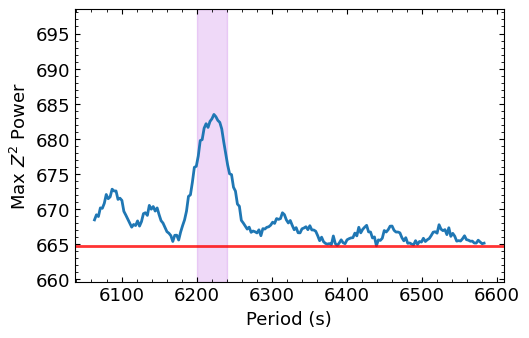

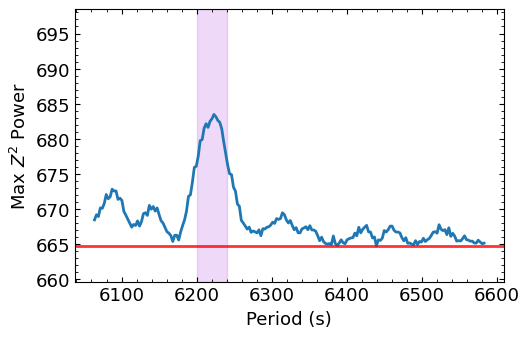

In [4]:
plotting.plot_demod_projection(Ts, max_powers, z2_null, best['z2_max'], path=f'{savedir}/demod_grid_{obs}.pdf')

## Section 4.2: control study

The search is repeated at trial periods between 70 s and 5000 s (spacing $\Delta T = T^2 / T_{\rm cont}$ with $T_{\rm cont} = 400$ ks),
with a coarser $(A, \varphi)$ grid, to sample the null distribution of the maximum $Z^2_1$.

In [5]:
T_tot = 400000
Ts_ctrl = make_T_grid(70, 5000, T_tot)
As_ctrl = np.linspace(0, 2, 5)
phis_ctrl = np.linspace(0, 2 * np.pi, 15, endpoint=False)
print(f'{len(Ts_ctrl)} control periods from {Ts_ctrl[0]:.1f} to {Ts_ctrl[-1]:.1f} s; {len(Ts_ctrl) * len(As_ctrl) * len(phis_ctrl):,} evaluations')

ctrl_file = f'{config.DATA_DIR}/control_study_z2_vs_T.npy'
if os.path.exists(ctrl_file):
    max_z2_ctrl = np.load(ctrl_file)
    assert np.array_equal(np.load(f'{config.DATA_DIR}/control_study_Ts.npy'), Ts_ctrl)
else:
    grid_ctrl = demodulate_grid_search_parallel(events.time, config.P_SPIN, Ts_ctrl, As_ctrl, phis_ctrl, nharm=nharm, n_workers=n_workers)
    max_z2_ctrl = project_to_period_axis(grid_ctrl, Ts_ctrl)
    np.save(ctrl_file, max_z2_ctrl)
    np.save(f'{config.DATA_DIR}/control_study_Ts.npy', Ts_ctrl)

5635 control periods from 70.0 to 4982.2 s; 422,625 evaluations


## False-alarm probability: counting estimate and exponential tail fit, both corrected for the $N_{\rm ind}$ independent trials of the search range

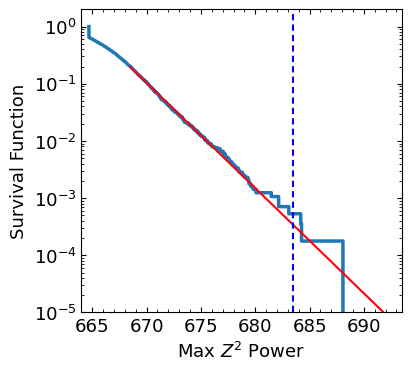

In [6]:
observed_z2 = best['z2_max']
N_control = len(Ts_ctrl)
N_ind = T_tot * (1 / 6064 - 1 / 6583)
N_exceed = int(np.sum(max_z2_ctrl >= observed_z2))
Q = N_exceed / (N_control / N_ind)

# Exponential fit to the upper 20% of the survival function S(z) = P(Z^2 > z)
sorted_z2 = np.sort(max_z2_ctrl)
survival = 1.0 - np.arange(1, len(sorted_z2) + 1) / len(sorted_z2)
n_fit = max(int(0.2 * len(sorted_z2)), 10)
x_fit, y_fit = sorted_z2[-n_fit:], survival[-n_fit:]
x_fit, y_fit = x_fit[y_fit > 0], y_fit[y_fit > 0]
slope, intercept = np.polyfit(x_fit, np.log(y_fit), 1)
fap = np.exp(slope * observed_z2 + intercept) * N_ind

plotting.plot_survival(sorted_z2, survival, x_fit[0], slope, intercept, observed_z2, z2_null, path=f'{savedir}/control_survival_{obs}.pdf')

## Numbers quoted in the paper

In [7]:
print(f"Rømer delay search: P_orb = {best['T']:.1f} s, A = {best['A']:.3f} s, phi = {np.degrees(best['phi']):.1f} deg")
print(f"Z^2_1 = {best['z2_max']:.1f} versus {z2_null:.1f} unmodulated (delta = {best['z2_max'] - z2_null:.1f})")
print(f'Control study: {N_control} trial periods, N_ind = {N_ind:.1f}, N_exceed = {N_exceed}, Q = {Q:.4f}')
print(f'Tail fit: log S = {slope:.4f} z + {intercept:.2f}; FAP = {fap:.2e}')

Rømer delay search: P_orb = 6223.1 s, A = 1.263 s, phi = 323.1 deg
Z^2_1 = 683.5 versus 664.7 unmodulated (delta = 18.8)
Control study: 5635 trial periods, N_ind = 5.2, N_exceed = 3, Q = 0.0028
Tail fit: log S = -0.4237 z + 281.61; FAP = 1.78e-03
